# Telecom Customer Churn Prediction and Retention Strategy

## 1. Introduction

### 1.1 Background

The telecommunications industry operates in a highly competitive environment where customers can switch service providers based on pricing, service quality, network reliability, customer support, and competing offers. Retaining existing customers is therefore an important business priority.

Customer churn refers to the situation in which a customer stops using a company's products or services. High churn can reduce recurring revenue, increase customer acquisition costs, and negatively affect long-term customer relationships.

With the growing availability of customer data, data analytics and machine learning can help telecommunications companies identify patterns associated with churn and recognise customers who may be at risk of leaving.

### 1.2 Business Problem

Telecom providers need to understand which customers are more likely to discontinue their services and what factors may be associated with their decisions. Without a systematic analytical approach, retention activities may be directed towards customers who are not at significant risk, while customers who need attention may be overlooked.

This project addresses the problem by analysing customer information, developing predictive models, and translating the findings into practical customer retention recommendations.

### 1.3 Project Aim

The primary aim of this project is to develop a data-driven approach to customer churn prediction and retention strategy by combining exploratory data analysis, machine learning, and business interpretation.

1.4 Project Objectives

Understand the structure, characteristics, and quality of the telecom customer dataset.

Explore customer behaviour and identify patterns associated with churn.

Examine relationships between customer characteristics, service experiences, and churn.

Develop and compare suitable machine-learning classification models.

Evaluate model performance using appropriate classification metrics.

Identify customer segments that may require targeted retention efforts.

Recommend practical retention strategies based on the analytical findings.


1.5 Business Value

The project aims to support better customer retention decisions by helping a telecom provider prioritise at-risk customers, investigate potential sources of dissatisfaction, and design more relevant retention initiatives. The potential business value includes improved customer experience, more efficient retention spending, and stronger long-term customer relationships.

1.7 Analytical Approach

The project will follow a structured analytical workflow:

Business Understanding → Data Understanding → Data Cleaning → Exploratory Data Analysis → Feature Engineering → Model Development → Model Evaluation → Retention Recommendations

The results will depend on the quality, completeness, and representativeness of the available dataset.

In [1]:
# Step 3.1: Required libraries

import pandas as pd
import numpy as np
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO

# Configure pandas to display all dataset columns
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Step 3.2: Load the telecom churn dataset

import pandas as pd
from zipfile import ZipFile
from io import BytesIO

#  Dataset file path
zip_path = "/content/4785892-Dataset_-_Churn_Prediction_and_Retention_Strategy_for_a_Telecom_Provider.zip"

with ZipFile(zip_path, "r") as outer_zip:

    print("Files in the main ZIP:")
    print(outer_zip.namelist())

    #  Nested ZIP file
    nested_zip_name = next(
        name for name in outer_zip.namelist()
        if name.lower().endswith(".zip")
    )

    nested_zip_bytes = outer_zip.read(nested_zip_name)

    with ZipFile(BytesIO(nested_zip_bytes), "r") as inner_zip:

        csv_filename = next(
            name for name in inner_zip.namelist()
            if name.lower().endswith(".csv")
        )

        # Load the CSV into a DataFrame
        with inner_zip.open(csv_filename) as csv_file:
            df = pd.read_csv(csv_file)

print("\nDataset loaded successfully.")
print("Dataset dimensions:", df.shape)

Files in the main ZIP:
['Datasets-20251227T121042Z-1-001.zip', 'Data Definition.xlsx', 'DS_Store.DS_Store']

Dataset loaded successfully.
Dataset dimensions: (25000, 36)


In [4]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the first five records
print("\nFirst five records:")
display(df.head())

Dataset shape: (25000, 36)

Column names:
['customer_id', 'gender', 'age', 'region_circle', 'connection_type', 'plan_type', 'contract_type', 'base_plan_category', 'tenure_months', 'monthly_charges', 'total_charges', 'avg_data_gb_month', 'avg_voice_mins_month', 'sms_count_month', 'overage_charges', 'is_family_plan', 'is_multi_service', 'network_issues_3m', 'dropped_call_rate', 'avg_data_speed_mbps', 'num_complaints_3m', 'num_complaints_12m', 'call_center_interactions_3m', 'last_complaint_resolution_days', 'app_logins_30d', 'selfcare_transactions_30d', 'auto_pay_enrolled', 'late_payment_flag_3m', 'avg_payment_delay_days', 'arpu', 'segment_value', 'nps_score', 'service_rating_last_6m', 'received_competitor_offer_flag', 'retention_offer_accepted_flag', 'is_churn']

First five records:


,customer_id,gender,age,region_circle,connection_type,plan_type,contract_type,base_plan_category,tenure_months,monthly_charges,total_charges,avg_data_gb_month,avg_voice_mins_month,sms_count_month,overage_charges,is_family_plan,is_multi_service,network_issues_3m,dropped_call_rate,avg_data_speed_mbps,num_complaints_3m,num_complaints_12m,call_center_interactions_3m,last_complaint_resolution_days,app_logins_30d,selfcare_transactions_30d,auto_pay_enrolled,late_payment_flag_3m,avg_payment_delay_days,arpu,segment_value,nps_score,service_rating_last_6m,received_competitor_offer_flag,retention_offer_accepted_flag,is_churn
0,100000,Female,23,West,4G,Postpaid,2 Year,Postpaid Platinum,84,1133.57,92927.66,10.69,453.0,102.0,0.00,1,0,1,0.035772,20.657628,1,1,2,3.3,8,3,0,0,0.4,1133.57,High,13.0,3.2,0,0,0
1,100001,Male,72,West,4G,Prepaid,No Contract,Prepaid Unlimited,32,683.24,19368.90,34.65,797.0,29.0,169.54,0,1,3,0.015473,11.957035,0,0,1,0.0,6,2,0,1,5.4,688.54,Medium,41.0,3.6,0,0,0
2,100002,Female,47,South,4G,Prepaid,No Contract,Prepaid Regular,119,307.04,36123.77,5.22,687.0,73.0,0.74,0,0,1,0.028856,21.120911,1,3,2,5.4,5,3,1,0,0.0,307.05,Low,53.0,5.0,0,0,0
3,100003,Female,74,West,4G,Prepaid,No Contract,Prepaid Mini,73,213.82,16476.90,24.49,232.0,0.0,78.21,1,0,0,0.033661,16.733437,0,1,0,0.0,7,5,1,0,0.0,214.89,Low,20.0,4.5,1,1,0
4,100004,Male,41,South,5G,Prepaid,No Contract,Prepaid Regular,92,383.17,37683.17,50.46,450.0,35.0,75.60,0,0,5,0.013339,8.692907,0,0,0,0.0,6,4,0,0,0.5,383.99,Low,17.0,2.6,0,0,0


In [5]:
# Check data types and non-null values in each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 36 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   customer_id                     25000 non-null  int64  
 1   gender                          25000 non-null  object 
 2   age                             25000 non-null  int64  
 3   region_circle                   25000 non-null  object 
 4   connection_type                 25000 non-null  object 
 5   plan_type                       25000 non-null  object 
 6   contract_type                   25000 non-null  object 
 7   base_plan_category              25000 non-null  object 
 8   tenure_months                   25000 non-null  int64  
 9   monthly_charges                 25000 non-null  float64
 10  total_charges                   25000 non-null  float64
 11  avg_data_gb_month               25000 non-null  float64
 12  avg_voice_mins_month            

### 3.4 Data Types and Completeness

In this step, we will examine the data type of each column and check how many non-null values it contains. This is important because the dataset may include numerical values, categorical variables, and missing observations.

Understanding these characteristics will help us identify columns that may require cleaning or conversion before conducting further analysis.

Step 3.5 — Data Quality Assessment
Before analysing customer behaviour, it is important to check whether the dataset contains missing values or duplicate records. These issues can affect the reliability of our analysis and may lead to misleading results if they are not handled appropriately.

In this step, we will examine missing values in each column and check for duplicate rows. We will first identify any issues and then decide whether corrective action is necessary.


In [6]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate the percentage of missing values
missing_percentage = (df.isnull().mean() * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

# Display columns containing missing values first
missing_summary = missing_summary.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage (%)
customer_id,0,0.0
gender,0,0.0
age,0,0.0
region_circle,0,0.0
connection_type,0,0.0
plan_type,0,0.0
contract_type,0,0.0
base_plan_category,0,0.0
tenure_months,0,0.0
monthly_charges,0,0.0


Step 3.5.3 — Summarise the findings

In [7]:
# Summarise the initial data quality checks
print("Total records:", len(df))
print("Total columns:", df.shape[1])
print("Total missing values:", int(df.isnull().sum().sum()))
print("Total duplicate rows:", int(df.duplicated().sum()))

Total records: 25000
Total columns: 36
Total missing values: 0
Total duplicate rows: 0


### 3.6 Descriptive Statistics

After checking for missing values and duplicate records, the next step is to examine the numerical characteristics of the dataset. Descriptive statistics help us understand the typical values, variation, and range of customer attributes.

This step provides an initial overview of the numerical variables and may help identify unusual values that require further investigation. These statistics describe the data but do not, by themselves, establish the reasons behind customer churn.

In [8]:
# Generate descriptive statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,25000.0,112499.500000,7217.022701,100000.00,106249.750000,112499.500000,118749.250000,124999.000000
age,25000.0,45.960200,16.401422,18.00,32.000000,46.000000,60.000000,74.000000
tenure_months,25000.0,60.149600,34.374772,1.00,31.000000,60.000000,90.000000,119.000000
monthly_charges,25000.0,475.518315,267.550787,99.00,300.607500,385.735000,601.250000,1603.490000
total_charges,25000.0,27230.695507,23717.163861,159.03,10310.812500,20840.650000,36884.147500,177878.030000
avg_data_gb_month,25000.0,25.107675,9.907997,0.50,18.390000,25.100000,31.820000,71.800000
avg_voice_mins_month,25000.0,602.187920,247.929808,30.00,432.000000,603.000000,770.250000,1848.000000
sms_count_month,25000.0,50.652920,28.547638,0.00,30.000000,50.000000,70.000000,173.000000
overage_charges,25000.0,55.209308,43.627134,0.00,23.517500,50.790000,79.060000,451.590000
is_family_plan,25000.0,0.248720,0.432280,0.00,0.000000,0.000000,0.000000,1.000000


### 3.7 Understanding the Target Variable

The target variable represents the outcome that the machine-learning model will attempt to predict. In this project, we expect the target variable to be `is_churn`.

We will examine the number and percentage of observations in each target class. This helps us understand whether churned and non-churned customers are represented equally in the dataset.



In [9]:
# Check whether the expected target column exists
if "is_churn" in df.columns:

    # Count observations in each churn category
    churn_counts = df["is_churn"].value_counts(dropna=False)

    # Calculate the percentage of each category
    churn_percentages = (
        df["is_churn"]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )

    # Combine counts and percentages
    churn_summary = pd.DataFrame({
        "Customer Count": churn_counts,
        "Percentage (%)": churn_percentages
    })

    display(churn_summary)

else:
    print("The column 'is_churn' was not found.")
    print("Available columns:", df.columns.tolist())

,Customer Count,Percentage (%)
is_churn,,
0,14643,58.57
1,10357,41.43


Step 3.7 — Interpretation
- is_churn = 0: 14,643 customers (58.57%).
- is_churn = 1: 10,357 customers (41.43%).
Important:  In the dataset’s data dictionary that 1 means a customer churned and 0 means a customer did not churn.

Step 4 — Exploratory Data Analysis (EDA)

EDA helps us understand the dataset’s patterns, identify unusual values and explore how customer characteristics relate to churn before building a model.

### 4.1 Distribution of Customer Churn

The first step in exploratory data analysis is to examine the distribution of the target variable, `is_churn`. This helps us understand how many customers have churned compared with those who have remained.


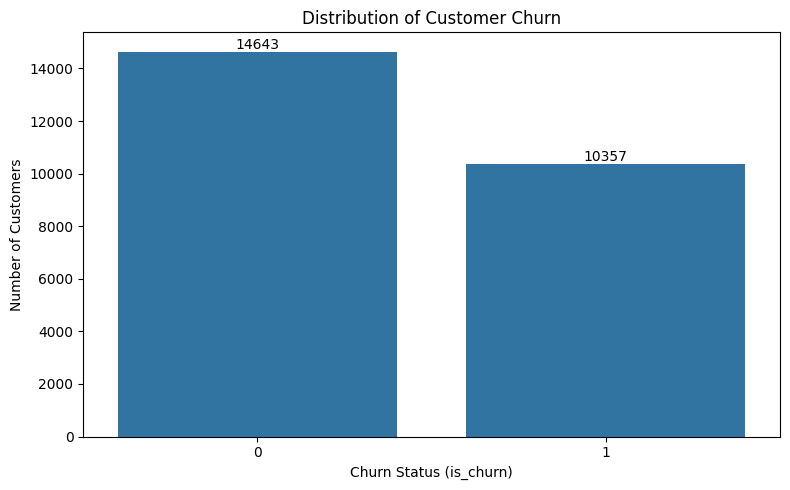

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

if "is_churn" in df.columns:
    plt.figure(figsize=(8, 5))

    ax = sns.countplot(data=df, x="is_churn")

    ax.set_title("Distribution of Customer Churn")
    ax.set_xlabel("Churn Status (is_churn)")
    ax.set_ylabel("Number of Customers")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f")

    plt.tight_layout()
    plt.show()
else:
    print("The target variable 'is_churn' was not found.")

Step 4.2 — Identify Numerical and Categorical Features
Before analysing which customer characteristics are associated with churn, we need to understand the types of variables in the dataset.
- Numerical features: Values that represent measurable quantities, such as monthly charges, tenure or total spending.
- Categorical features: Values that represent groups or labels, such as contract type, payment method or internet service.
- Identifier columns: Values such as customer IDs that identify records but generally do not directly explain churn.

### 4.2 Understanding Feature Types

The dataset contains different types of variables, and each type requires an appropriate analysis method. Numerical variables can be examined using measures such as the mean, median and standard deviation, while categorical variables can be analysed using frequency tables and bar charts.

Identifying feature types also helps us prepare the data correctly for machine learning. For example, categorical variables may need to be encoded before they can be used by a classification algorithm.


In [11]:
# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

print("\nNumber of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))

Numerical columns:
['customer_id', 'age', 'tenure_months', 'monthly_charges', 'total_charges', 'avg_data_gb_month', 'avg_voice_mins_month', 'sms_count_month', 'overage_charges', 'is_family_plan', 'is_multi_service', 'network_issues_3m', 'dropped_call_rate', 'avg_data_speed_mbps', 'num_complaints_3m', 'num_complaints_12m', 'call_center_interactions_3m', 'last_complaint_resolution_days', 'app_logins_30d', 'selfcare_transactions_30d', 'auto_pay_enrolled', 'late_payment_flag_3m', 'avg_payment_delay_days', 'arpu', 'nps_score', 'service_rating_last_6m', 'received_competitor_offer_flag', 'retention_offer_accepted_flag', 'is_churn']

Categorical columns:
['gender', 'region_circle', 'connection_type', 'plan_type', 'contract_type', 'base_plan_category', 'segment_value']

Number of numerical columns: 29
Number of categorical columns: 7


In [13]:
# A summary of columns and their data types

feature_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique(dropna=False).values
})

display(feature_summary)

,Column,Data Type,Unique Values
0,customer_id,int64,25000
1,gender,object,3
2,age,int64,57
3,region_circle,object,5
4,connection_type,object,3
5,plan_type,object,2
6,contract_type,object,4
7,base_plan_category,object,6
8,tenure_months,int64,119
9,monthly_charges,float64,20699


Step 4.3 — Analyse Churn by Categorical Features
The next step is to examine whether churn rates differ across customer groups. For example, customers with different contract types or payment methods may show different churn patterns.

We should first identify the actual categorical columns in your dataset rather than assume which variables it contains.

In [15]:
# Identify categorical features

target = "is_churn"

categorical_features = [
    col for col in df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns
    if col != target and df[col].nunique(dropna=False) <= 20
]

print("Categorical features selected for analysis:")
print(categorical_features)

Categorical features selected for analysis:
['gender', 'region_circle', 'connection_type', 'plan_type', 'contract_type', 'base_plan_category', 'segment_value']


In [16]:
# Calculate churn rate for each category

if target in df.columns:
    for col in categorical_features:
        print(f"\nChurn analysis by: {col}")

        summary = (
            df.groupby(col, dropna=False)[target]
            .agg(
                Customer_Count="count",
                Churn_Rate="mean"
            )
            .reset_index()
        )

        summary["Churn_Rate_%"] = (
            summary["Churn_Rate"] * 100
        ).round(2)

        summary = summary.drop(columns="Churn_Rate")
        display(summary)
else:
    print(f"Target column '{target}' was not found.")


Churn analysis by: gender


,gender,Customer_Count,Churn_Rate_%
0,Female,12070,41.38
1,Male,11940,41.75
2,Other,990,38.18



Churn analysis by: region_circle


,region_circle,Customer_Count,Churn_Rate_%
0,East,4578,41.59
1,Metro,4961,42.17
2,North,5615,40.98
3,South,5382,40.97
4,West,4464,41.55



Churn analysis by: connection_type


...

,contract_type,Customer_Count,Churn_Rate_%
0,1 Year,2147,31.21
1,2 Year,742,23.32
2,Month-to-Month,4589,32.82
3,No Contract,17522,45.70



Churn analysis by: base_plan_category


,base_plan_category,Customer_Count,Churn_Rate_%
0,Postpaid Gold,2999,31.21
1,Postpaid Platinum,1508,30.50
2,Postpaid Silver,2971,32.08
3,Prepaid Mini,5265,45.83
4,Prepaid Regular,8755,44.83
5,Prepaid Unlimited,3502,47.69



Churn analysis by: segment_value


,segment_value,Customer_Count,Churn_Rate_%
0,High,3029,31.13
1,Low,13121,45.24
2,Medium,8850,39.30


Step 4.4 — Visualise Churn Rates Across Categorical Features
In the previous step, we calculated churn rates for different customer groups. Now we will visualise those results to make comparisons easier.

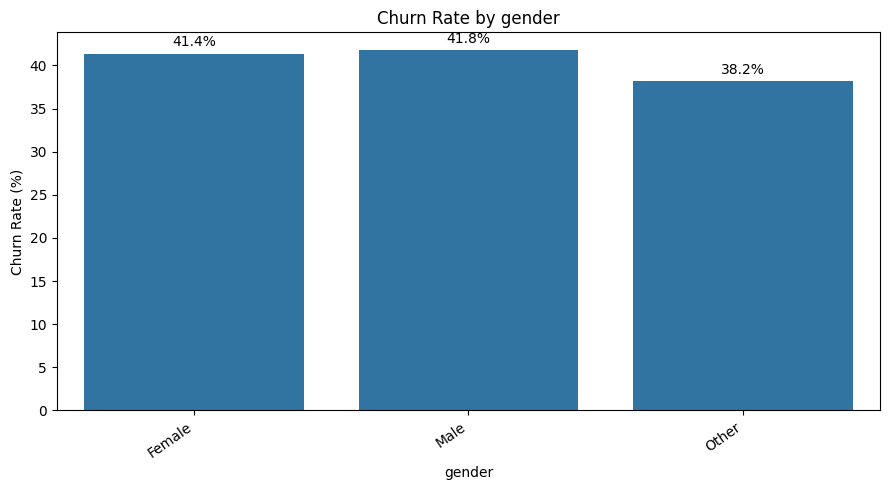

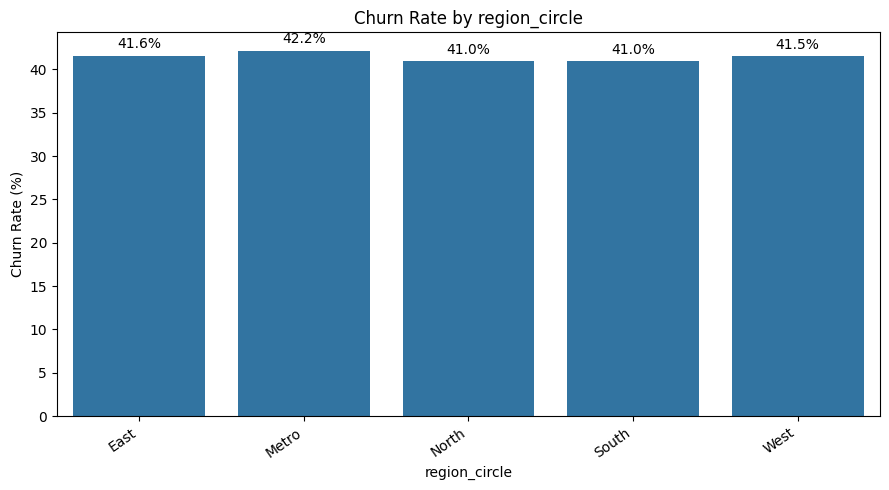

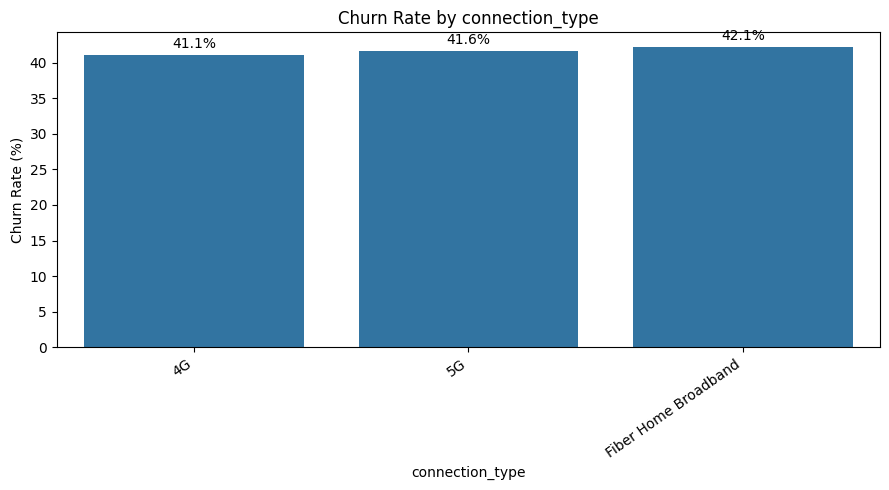

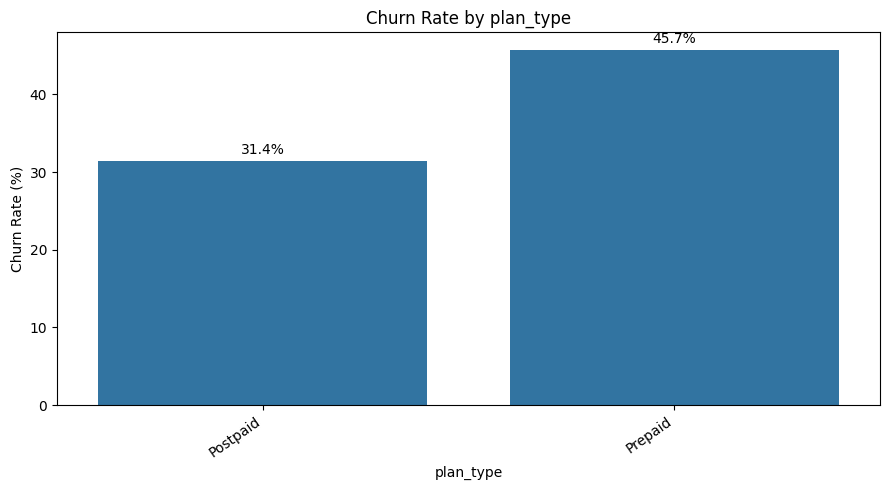

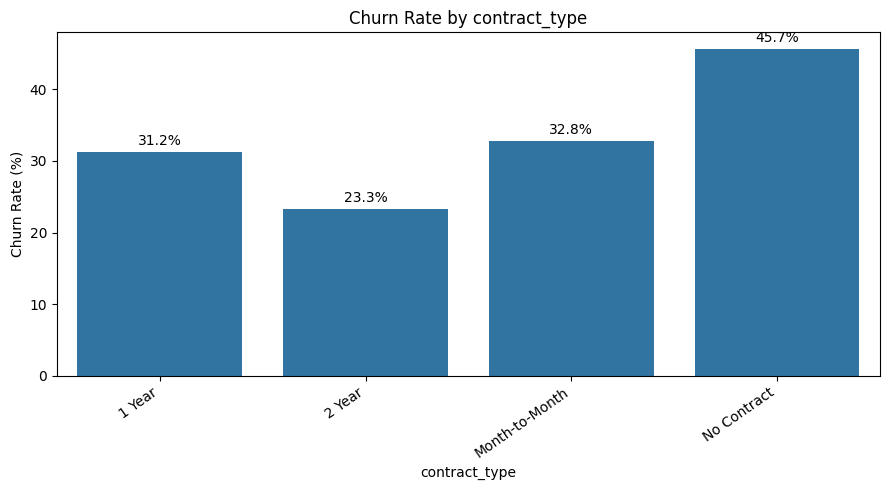

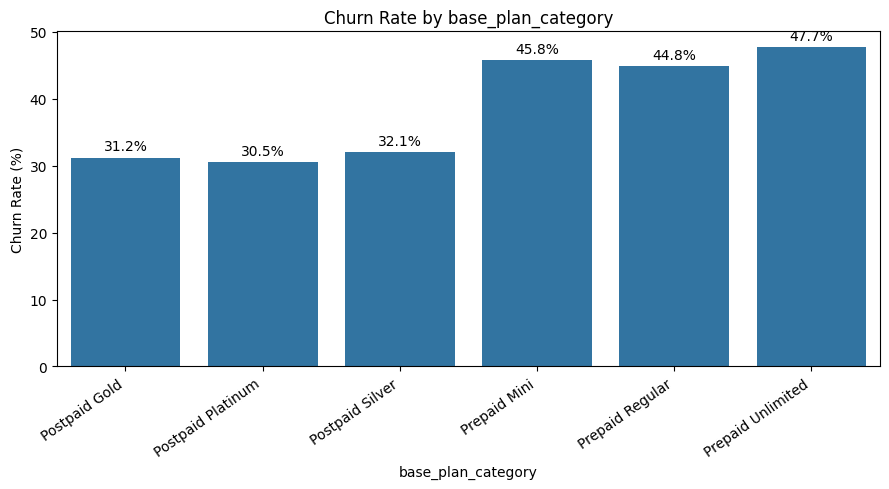

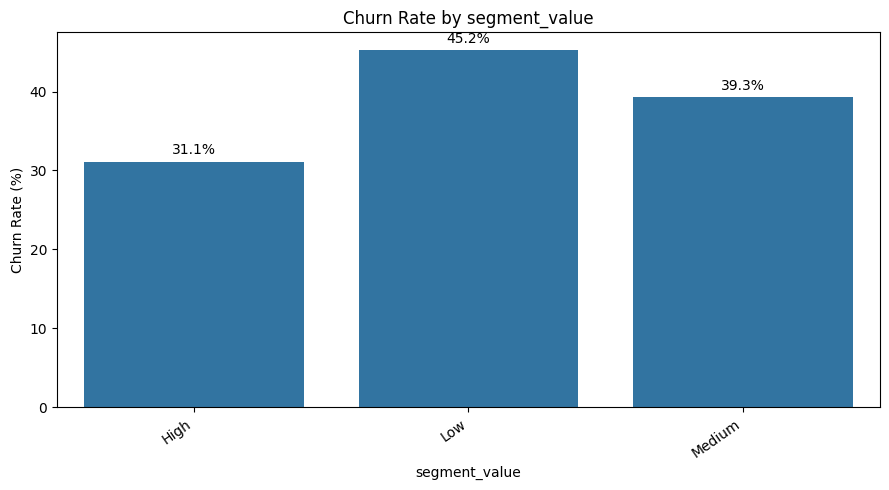

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

target = "is_churn"

if target in df.columns:
    categorical_features = [
        col for col in df.select_dtypes(
            include=["object", "category", "bool"]
        ).columns
        if col != target and 1 < df[col].nunique(dropna=False) <= 10
    ]

    if categorical_features:
        for col in categorical_features:
            plot_data = df[[col, target]].copy()
            plot_data[target] = pd.to_numeric(
                plot_data[target], errors="coerce"
            )
            plot_data = plot_data.dropna(subset=[target])

            churn_rates = (
                plot_data.groupby(col, dropna=False)[target]
                .mean()
                .mul(100)
                .reset_index(name="Churn Rate (%)")
            )

            churn_rates["Churn Rate (%)"] = (
                churn_rates["Churn Rate (%)"].round(2)
            )

            plt.figure(figsize=(9, 5))
            ax = sns.barplot(
                data=churn_rates,
                x=col,
                y="Churn Rate (%)"
            )

            ax.set_title(f"Churn Rate by {col}")
            ax.set_xlabel(col)
            ax.set_ylabel("Churn Rate (%)")
            plt.xticks(rotation=35, ha="right")
            ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
            plt.tight_layout()
            plt.show()
    else:
        print("No suitable categorical features were found.")
else:
    print("Target variable 'is_churn' was not found.")

Step 4.5 — Numerical Feature Analysis
Now we will examine numerical variables and compare their distributions for customers who churned and those who did not. This can help us identify which variables may be useful for predicting churn.

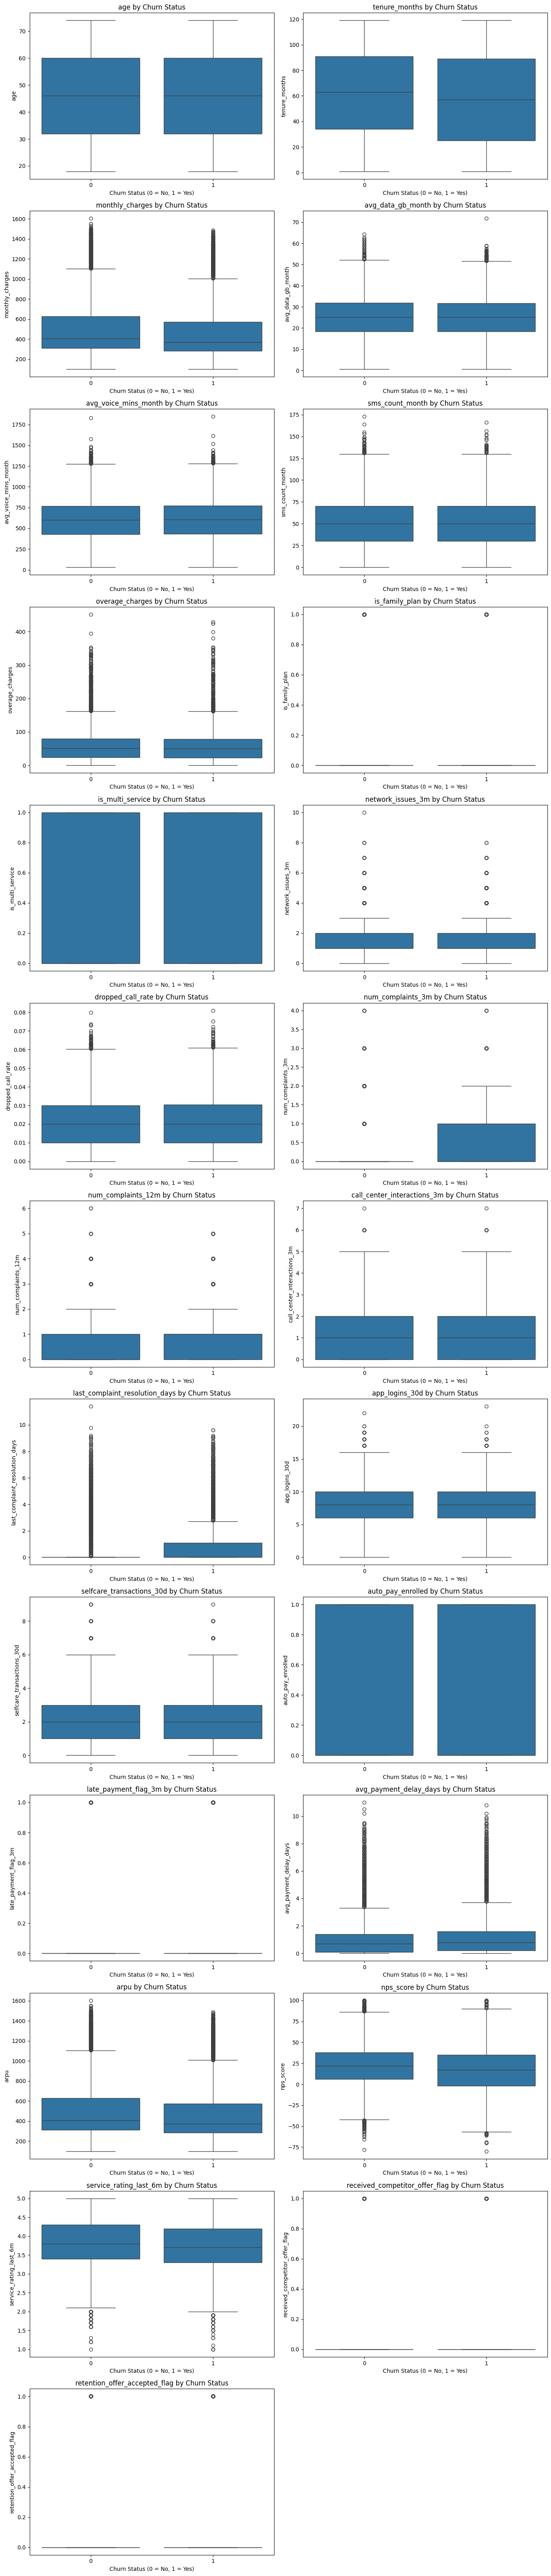

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

target = "is_churn"

if target not in df.columns:
    print("Target variable 'is_churn' was not found.")
elif not numerical_features:
    print("No numerical features are available for analysis.")
else:
    # Exclude numeric identifier-like columns with a unique value per row
    features_to_plot = [
        col for col in numerical_features
        if df[col].nunique(dropna=True) < len(df) * 0.95
    ]

    if not features_to_plot:
        print("No suitable numerical features were identified.")
    else:
        n_cols = 2
        n_rows = math.ceil(len(features_to_plot) / n_cols)

        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(14, 5 * n_rows)
        )
        axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

        for i, col in enumerate(features_to_plot):
            sns.boxplot(
                data=df,
                x=target,
                y=col,
                ax=axes[i]
            )
            axes[i].set_title(f"{col} by Churn Status")
            axes[i].set_xlabel("Churn Status (0 = No, 1 = Yes)")
            axes[i].set_ylabel(col)

        for j in range(len(features_to_plot), len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.show()

Median line: The middle value for that group.



Box: The middle 50% of observations.



Whiskers and points beyond them: Show the spread and potential outliers under the plotting convention.



Differences between churn groups: Suggest possible relationships that may be worth testing.

### 4.6 Numerical Feature Comparison

In this step, we compare numerical features across the two churn groups using their mean and median values. This helps us identify differences in customer behaviour and understand which variables may be useful for churn prediction.

In [20]:
# Compare numerical features by churn status

numerical_features = [
    col for col in df.select_dtypes(include="number").columns
    if col != "is_churn" and df[col].nunique() < len(df) * 0.95
]

comparison = df.groupby("is_churn")[numerical_features].agg(
    ["mean", "median"]
).round(2)

display(comparison)

age        tenure_months        monthly_charges         avg_data_gb_month        avg_voice_mins_month  \
           mean median          mean median            mean  median              mean median                 mean   
is_churn                                                                                                            
0         46.05   46.0         62.16   63.0          495.95  404.85             25.12  25.07               600.68   
1         45.84   46.0         57.30   57.0          446.64  370.43             25.09  25.13               604.32   

                sms_count_month        overage_charges        is_family_plan        is_multi_service         \
         median            mean median            mean median           mean median             mean median   
is_churn                                                                                                      
0         601.0           50.67   50.0           55.55  50.99           0.25    0.0              0.3    0.0   
1         606.0           50.62   50.0           54.72  50.45           0.25    0.0              0.3    0.0   

         network_issues_3m        dropped_call_rate        num_complaints_3m        num_complaints_12m         \
                      mean median              mean median              mean median               mean median   
is_churn                                                                                                        
0                      1.4    1.0              0.02   0.02              0.26    0.0               0.65    0.0   
1                      1.6    1.0              0.02   0.02              0.36    0.0               0.76    1.0   

         call_center_interactions_3m        last_complaint_resolution_days        app_logins_30d         \
                                mean median                           mean median           mean median   
is_churn                                                                                                  
0                               1.07    1.0                           0.69    0.0           7.99    8.0   
1                               1.16    1.0                           0.94    0.0           8.05    8.0   

         selfcare_transactions_30d        auto_pay_enrolled        late_payment_flag_3m        avg_payment_delay_days  \
                              mean median              mean median                 mean median                   mean   
is_churn                                                                                                                
0                             2.00    2.0               0.4    0.0                 0.18    0.0                   1.20   
1                             1.98    2.0               0.4    0.0                 0.23    0.0                   1.41   

                   arpu         nps_score        service_rating_last_6m        received_competitor_offer_flag         \
         median    mean  median      mean median                   mean median                           mean median   
is_churn                                                                                                               
0           0.7  498.00  407.23     22.07   22.0                   3.84    3.8                           0.13    0.0   
1           0.8  449.67  373.26     17.30   17.0                   3.72    3.7                           0.19    0.0   

         retention_offer_accepted_flag         
                                  mean median  
is_churn                                       
0                                  0.1    0.0  
1                                  0.1    0.0

Next: Step 4.7 — Check Correlation Between Numerical Features
### 4.7 Correlation Analysis

Correlation analysis measures the strength and direction of the relationship between numerical variables. Values closer to `1` indicate a positive relationship, values closer to `-1` indicate a negative relationship, and values near `0` indicate a weak linear relationship.

Correlation does not prove causation.

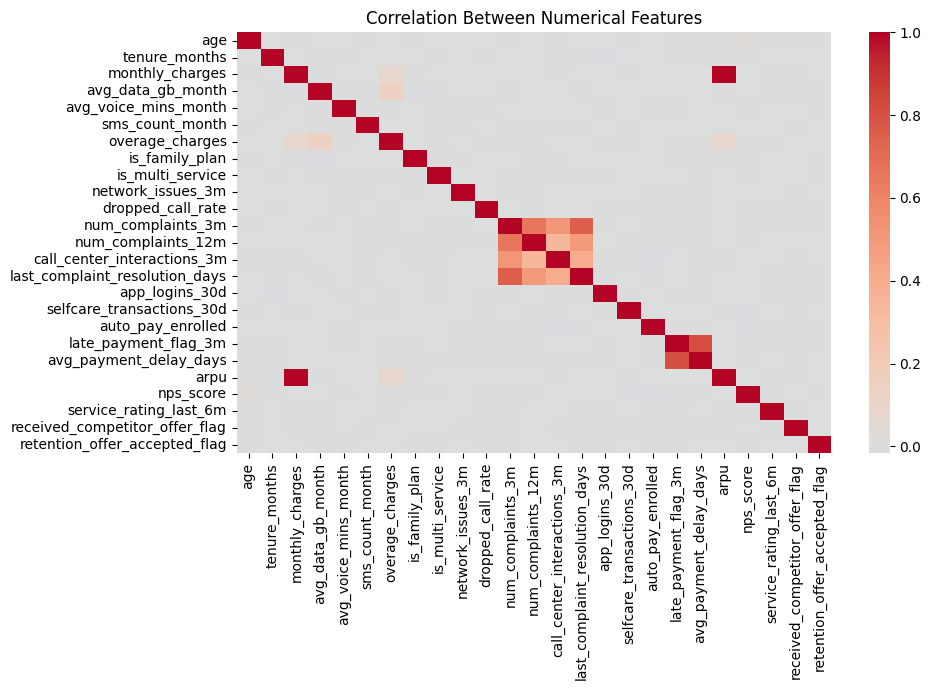

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_data = df[numerical_features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_data,
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

Step 5 — Data Preparation for Machine Learning
Now we move from exploring the dataset to preparing it for model building. First, we will check missing values and duplicate records again before deciding how to handle them.
## 5. Data Preparation

Before training a machine-learning model, we need to ensure that the data is suitable for analysis. This includes checking missing values, duplicate records and the target variable.

We will review the data quality first and then prepare the features for model training.

In [22]:
# Check data quality before model preparation

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

Missing values: 0
Duplicate rows: 0


,Missing Values
customer_id,0
gender,0
age,0
region_circle,0
connection_type,0
plan_type,0
contract_type,0
base_plan_category,0
tenure_months,0
monthly_charges,0


In [23]:
# Check target values and their counts

print(df["is_churn"].value_counts(dropna=False))
print("\nTarget data type:", df["is_churn"].dtype)

is_churn
0    14643
1    10357
Name: count, dtype: int64

Target data type: int64


Step 5.3 — Separate Features and Target
### 5.3 Separating Features and Target

For machine learning, we separate the dataset into input features (`X`) and the target variable (`y`).

- `X` contains the customer information used to predict churn.
- `y` contains the actual churn status that the model will learn to predict.

We will also identify columns that should not be used as predictive features, such as customer identifiers.

In [24]:
# Separate the target from the input features

target = "is_churn"

# Identify likely identifier columns for review
id_columns = [
    col for col in df.columns
    if col.lower() in ["customer_id", "customerid", "id"]
]

print("Potential identifier columns:", id_columns)

X = df.drop(columns=[target] + id_columns)
y = df[target].copy()

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", sorted(y.unique()))

Potential identifier columns: ['customer_id']

Feature matrix shape: (25000, 34)
Target shape: (25000,)
Target classes: [np.int64(0), np.int64(1)]


Step 5.4 — Identify Numerical and Categorical Inputs


In [25]:
# Identify feature types in X

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['age', 'tenure_months', 'monthly_charges', 'total_charges', 'avg_data_gb_month', 'avg_voice_mins_month', 'sms_count_month', 'overage_charges', 'is_family_plan', 'is_multi_service', 'network_issues_3m', 'dropped_call_rate', 'avg_data_speed_mbps', 'num_complaints_3m', 'num_complaints_12m', 'call_center_interactions_3m', 'last_complaint_resolution_days', 'app_logins_30d', 'selfcare_transactions_30d', 'auto_pay_enrolled', 'late_payment_flag_3m', 'avg_payment_delay_days', 'arpu', 'nps_score', 'service_rating_last_6m', 'received_competitor_offer_flag', 'retention_offer_accepted_flag']

Categorical features: ['gender', 'region_circle', 'connection_type', 'plan_type', 'contract_type', 'base_plan_category', 'segment_value']


Step 5.5 — Split Data into Training and Testing Sets

### 5.5 Train-Test Split

The dataset is divided into training and testing sets. The training set is used to train the model, while the testing set evaluates its performance on unseen data.

We will use an 80:20 split and stratify by the target variable to maintain approximately the same churn-class proportions in both sets.

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (20000, 34)
Testing features: (5000, 34)

Training target distribution:
is_churn
0    58.57
1    41.43
Name: proportion, dtype: float64

Testing target distribution:
is_churn
0    58.58
1    41.42
Name: proportion, dtype: float64


80% of the records are used for training.



20% are held back for testing.

Step 5.6 — Build a Preprocessing Pipeline

### 5.6 Preparing Features for Modelling

Machine-learning models generally cannot work directly with missing values or text categories. We will use a preprocessing pipeline to fill missing numerical values with the median, fill missing categorical values with the most frequent category, and encode categorical variables using one-hot encoding.

The preprocessing steps will be fitted on the training data only to avoid information leakage from the test set.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")

Numerical features: 27
Categorical features: 7
Preprocessing pipeline created successfully.


nxt
Step 6 — Train the First Machine Learning Model
We will start with Logistic Regression as our baseline model. It is commonly used for binary classification problems, such as predicting whether a customer will churn.

## 6. Model Building — Logistic Regression

Logistic Regression is a classification algorithm used to estimate the probability of an outcome. In this project, it will predict whether a customer is likely to churn (`1`) or not churn (`0`).

We will use Logistic Regression as our baseline model and evaluate its performance before trying other algorithms.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### 6.1 Generating Predictions

After training, we use the model to predict churn status for the testing dataset. These predictions will be compared with the actual outcomes to evaluate how well the model performs on unseen customer records.

In [29]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Actual values:", y_test.iloc[:10].tolist())
print("Predicted values:", y_pred[:10].tolist())
print("Predicted churn probabilities:", y_prob[:10].round(3).tolist())

Actual values: [0, 0, 0, 1, 0, 1, 0, 0, 1, 0]
Predicted values: [0, 1, 0, 0, 0, 1, 0, 0, 1, 0]
Predicted churn probabilities: [0.366, 0.523, 0.467, 0.361, 0.411, 0.647, 0.348, 0.496, 0.522, 0.233]


Step 6.2 — Evaluate Model Performance
Now we will check how well Logistic Regression predicts customer churn

### 6.2 Model Evaluation

We evaluate the model by comparing its predictions with the actual churn status in the test dataset. We will use accuracy, precision, recall, F1-score and ROC-AUC to understand its performance from different perspectives.

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.6344
Precision: 0.5995
Recall: 0.3535
F1-score: 0.4447
ROC-AUC: 0.6508

Classification Report:

              precision    recall  f1-score   support

           0       0.65      0.83      0.73      2929
           1       0.60      0.35      0.44      2071

    accuracy                           0.63      5000
   macro avg       0.62      0.59      0.59      5000
weighted avg       0.63      0.63      0.61      5000




- Accuracy: Overall proportion of correct predictions.
- Precision: Of customers predicted to churn, how many actually churned?
- Recall: Of customers who actually churned, how many did the model identify?
- F1-score: Balance between precision and recall.
- ROC-AUC: How well the model ranks churned customers above non-churned customers across different thresholds. A value near 0.5 indicates performance close to random ranking.

Step 6.3 — Confusion Matrix
### 6.3 Confusion Matrix

The confusion matrix shows the number of correct and incorrect predictions for each churn class. It helps us understand whether the model is missing customers who churn or incorrectly flagging customers who stay.

,Predicted: No Churn (0),Predicted: Churn (1)
Actual: No Churn (0),2440,489
Actual: Churn (1),1339,732


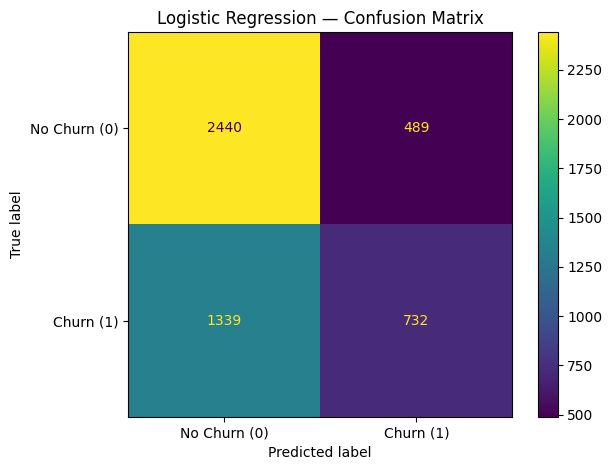

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display(
    pd.DataFrame(
        cm,
        index=["Actual: No Churn (0)", "Actual: Churn (1)"],
        columns=["Predicted: No Churn (0)", "Predicted: Churn (1)"]
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn (0)", "Churn (1)"]
).plot(values_format="d")

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

Step 7 — Train a Decision Tree Model
Now we will train a second model and compare its performance with Logistic Regression.

A Decision Tree makes predictions using a series of rules, similar to a flowchart. It can capture non-linear patterns in customer data.


In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        random_state=42,
        class_weight="balanced"
    ))
])

decision_tree_model.fit(X_train, y_train)

dt_pred = decision_tree_model.predict(X_test)
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


### 7.1 Decision Tree Evaluation

We will measure the Decision Tree's performance using accuracy, precision, recall, F1-score and ROC-AUC. Using the same metrics and test data allows us to compare it fairly with Logistic Regression.

In [33]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, dt_pred),
    "Precision": precision_score(y_test, dt_pred, zero_division=0),
    "Recall": recall_score(y_test, dt_pred, zero_division=0),
    "F1-score": f1_score(y_test, dt_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, dt_prob)
}

display(pd.DataFrame([dt_results]).round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.6046,0.5222,0.5345,0.5283,0.6193


Step 7.2 — Compare both models

In [34]:
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

comparison_df = pd.DataFrame([lr_results, dt_results])

display(
    comparison_df.set_index("Model").round(4)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.6344,0.5995,0.3535,0.4447,0.6508
Decision Tree,0.6046,0.5222,0.5345,0.5283,0.6193


### 7.3 Comparison of Classification Models

Logistic Regression achieved higher accuracy, precision and ROC-AUC than the Decision Tree. However, the Decision Tree achieved higher recall and F1-score.

For a customer-retention project, recall is important because it measures how many actual churn cases the model identifies. The Decision Tree identified churn cases more effectively at the current classification threshold, while Logistic Regression produced fewer false-positive predictions proportionally.

Neither model is clearly superior for every business objective. The final choice should consider retention costs, the cost of missing potential churners, and performance on unseen data.

## 8. Feature Importance Analysis

Feature importance estimates how much each feature contributes to the Decision Tree's predictions. We will use these values to identify the features the model relies on most when predicting customer churn.

These values indicate predictive usefulness within this model; they do not prove that a feature causes churn.

In [35]:
# Extract feature importance from the trained Decision Tree

trained_tree = decision_tree_model.named_steps["classifier"]
fitted_preprocessor = decision_tree_model.named_steps["preprocessing"]

feature_names = fitted_preprocessor.get_feature_names_out()
importance_values = trained_tree.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

,Feature,Importance
43,categorical__contract_type_No Contract,0.2110
23,numeric__nps_score,0.2052
1,numeric__tenure_months,0.1404
24,numeric__service_rating_last_6m,0.1135
25,numeric__received_competitor_offer_flag,0.0873
13,numeric__num_complaints_3m,0.0469
21,numeric__avg_payment_delay_days,0.0329
2,numeric__monthly_charges,0.0221
16,numeric__last_complaint_resolution_days,0.0216
10,numeric__network_issues_3m,0.0196


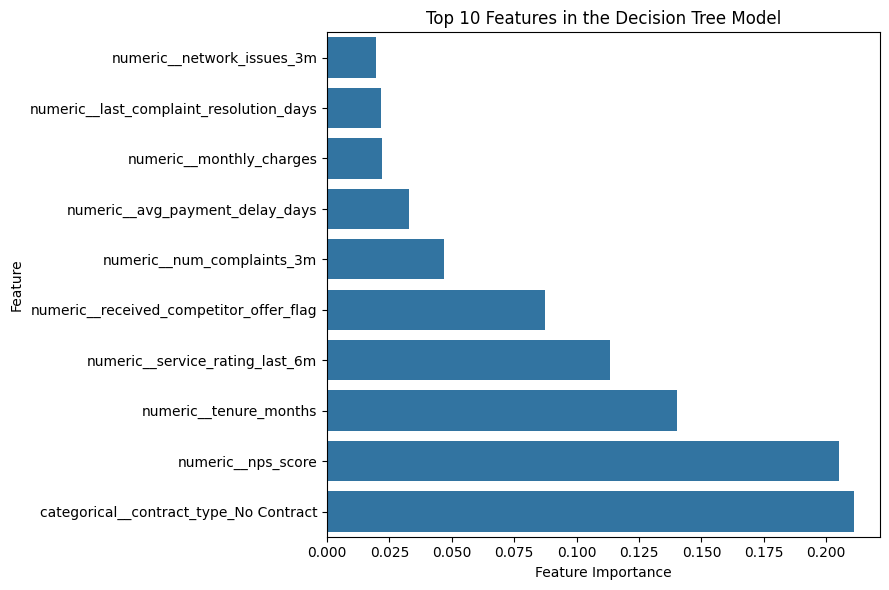

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Features in the Decision Tree Model")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 9. Customer Retention Strategy

The objective of churn prediction is not only to identify customers who may leave, but also to help the telecom provider take preventive action.

A practical retention strategy should focus on early identification of at-risk customers, understanding their concerns, providing relevant solutions and monitoring the results of retention efforts.

The following strategy outlines how the telecom provider can use churn predictions to support customer retention.

### 9.1 Recommended Retention Actions

**1. Early Identification**

Use the trained model to identify customers with a high predicted probability of churn. Prioritise these customers for further review.

**2. Understand Customer Concerns**

Review customer feedback, complaints, service quality and billing issues to understand the possible reasons behind churn risk.

**3. Personalised Retention Offers**

Offer suitable solutions based on the customer's needs, such as a relevant plan, a loyalty benefit or a billing review. Avoid providing unnecessary discounts to every at-risk customer.

**4. Improve Customer Experience**

Resolve recurring service problems, improve complaint handling and make customer support more responsive.

**5. Monitor Retention Results**

Track whether contacted customers remain active and compare campaign costs with the value of customers retained. Use these findings to improve future retention efforts.


In [37]:
retention_strategy = pd.DataFrame({
    "Customer Situation": [
        "High predicted churn risk",
        "Repeated service complaints",
        "Billing concerns",
        "Customers responding to retention offers"
    ],
    "Recommended Action": [
        "Prioritise for proactive outreach",
        "Investigate and resolve service issues",
        "Review billing and explain suitable plans",
        "Track retention and campaign cost"
    ],
    "Performance Measure": [
        "Contact and retention rates",
        "Complaint resolution time",
        "Billing-related complaint rate",
        "Retention rate and cost per retained customer"
    ]
})

display(retention_strategy)

,Customer Situation,Recommended Action,Performance Measure
0,High predicted churn risk,Prioritise for proactive outreach,Contact and retention rates
1,Repeated service complaints,Investigate and resolve service issues,Complaint resolution time
2,Billing concerns,Review billing and explain suitable plans,Billing-related complaint rate
3,Customers responding to retention offers,Track retention and campaign cost,Retention rate and cost per retained customer


Step 10 — Project Conclusion and Limitations

## 10. Conclusion

This project used telecom customer data to explore churn patterns and develop machine-learning models for predicting customer churn.

Two classification models, Logistic Regression and Decision Tree, were evaluated using a separate test dataset. Logistic Regression achieved 63.44% accuracy and a ROC-AUC score of 0.6508, while Decision Tree achieved 60.46% accuracy and a higher recall of 53.45%.

The results show that both models have potential for identifying customers at risk of leaving, although their predictive performance has room for improvement. The analysis can support a data-driven retention strategy by helping the telecom provider prioritise customers for further investigation and targeted retention efforts.

The models should be improved and validated before being used for real business decisions.

Limitations
### 10.1 Project Limitations

1. **Model performance:** Both models have limited predictive performance and may miss customers who eventually churn.
2. **Feature availability:** Prediction quality depends on the relevance and quality of the available customer data.
3. **Interpretation:** Observed relationships do not prove that a customer characteristic causes churn.
4. **Business validation:** The proposed retention strategies have not been tested through an actual retention campaign.
5. **Further improvement:** Additional model tuning, feature engineering and evaluation could improve results.

These limitations should be considered before applying the findings to real-world telecom operations.


In [38]:
# Save model comparison results

comparison_df.to_csv(
    "telecom_churn_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.
